# Final Project - Computer Vision

###  Vasileios Troupis

##### Imports 

In [1]:
# matplotlib

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# numpy
import numpy as np

# skimage
import skimage 
from skimage import measure
from skimage.filters import threshold_otsu
import skimage as image_tool

# scipy
import scipy
import scipy.ndimage

## Functions 

##### RGB to Grayscale Conversion

In [2]:
def rgb2gray(rgb):
    r, g, b = rgb[:,:,0], rgb[:,:,1], rgb[:,:,2]
    gray = 0.2989 * r + 0.5870 * g + 0.1140 * b

    return gray

# Step 1 

---


Load the input image `brain_tumors.jpg` for further processing.

---


In [3]:
image = mpimg.imread('../data/brain_tumors.jpg')

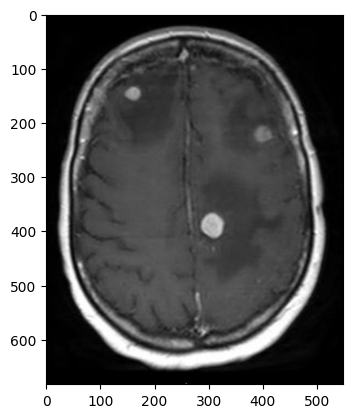

In [4]:
plt.imshow(image, cmap = 'gray')

#### Convert the RGB Image to Grayscale

---
The input image is converted to grayscale so that the subsequent
thresholding operations can be applied to a single-channel intensity image.

---

In [5]:
# Convert the original RGB image to grayscale for further processing.
grayscale_image = rgb2gray(image)

Text(0.5, 1.0, 'Grayscale Image')

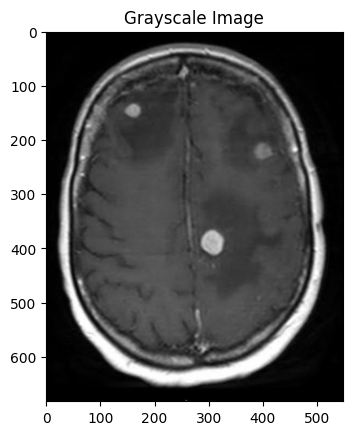

In [6]:
plt.figure()
plt.imshow(grayscale_image, cmap = 'gray')
plt.title('Grayscale Image')

# Step 2

In [7]:
# Apply manual thresholding to create a binary image.

thresh = 50
binary_image_manual = grayscale_image > thresh
binary_image_manual = binary_image_manual.astype(int)

# Apply Otsu's method to automatically determine the threshold value.

thresh = threshold_otsu(grayscale_image)
binary_image_otsu = grayscale_image > thresh
binary_image_otsu = binary_image_otsu.astype(int)

Text(0.5, 1.0, 'Binary Image Otsu')

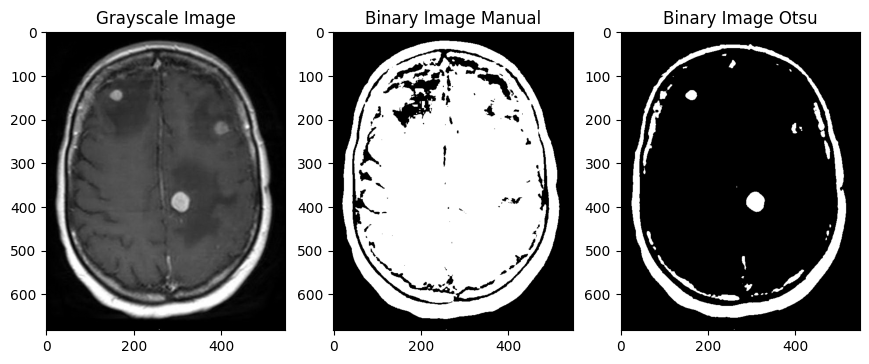

In [8]:
figure = plt.figure(figsize=(10.5, 10.5))

subplot = plt.subplot(1,3,1)
plt.imshow(grayscale_image,cmap = "gray")
subplot.set_title('Grayscale Image')

subplot = plt.subplot(1,3,2)
plt.imshow(binary_image_manual,cmap = "gray")
subplot.set_title('Binary Image Manual')

subplot = plt.subplot(1,3,3)
plt.imshow(binary_image_otsu,cmap = "gray")
subplot.set_title('Binary Image Otsu')


---------------------------------------------------------------------------------------------------------------------------


A manual threshold value of 50 does not separate the regions of interest
clearly enough, so a second threshold value of 100 is evaluated.

---------------------------------------------------------------------------------------------------------------------------


In [9]:
# Apply manual thresholding to create a binary image.

thresh = 100
binary_image_manual = grayscale_image > thresh
binary_image_manual = binary_image_manual.astype(int)

# Apply Otsu's method to automatically determine the threshold value.

thresh = threshold_otsu(grayscale_image)
binary_image_otsu = grayscale_image > thresh
binary_image_otsu = binary_image_otsu.astype(int)

Text(0.5, 1.0, 'Binary Image Otsu')

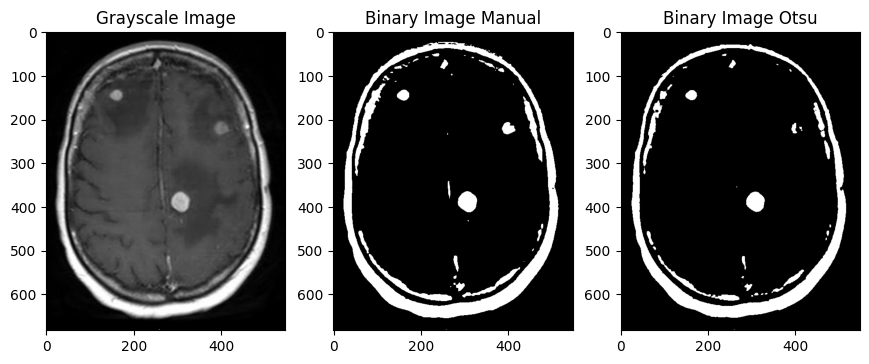

In [10]:
figure = plt.figure(figsize=(10.5, 10.5))

subplot = plt.subplot(1,3,1)
plt.imshow(grayscale_image, cmap = "gray")
subplot.set_title('Grayscale Image')

subplot = plt.subplot(1,3,2)
plt.imshow(binary_image_manual, cmap = "gray")
subplot.set_title('Binary Image Manual')

subplot = plt.subplot(1,3,3)
plt.imshow(binary_image_otsu, cmap = "gray")
subplot.set_title('Binary Image Otsu')


---

For this specific image, a manual threshold of 100 provides a clearer
visual separation of the target regions than the result obtained with
Otsu's automatic thresholding. Therefore, the manually thresholded image
is used in the following steps.

---

# Step 3

---
Connected-component labeling is applied to the binary image so that each
separate region receives a unique label. This allows the regions of
interest to be inspected and selected individually.

---

In [11]:
# Label connected components in the binary image
# and retrieve the total number of detected regions.
[Labeled_image, num_of_neighbors] = measure.label(binary_image_manual,  connectivity = 1, background = False, return_num = True)
Group_connected_list = image_tool.measure.regionprops(Labeled_image)

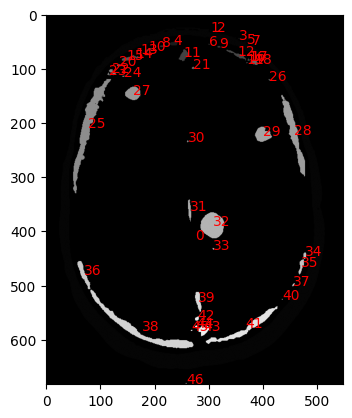

In [12]:
plt.figure()
plt.imshow(Labeled_image, cmap = plt.cm.gray)

for i in range(num_of_neighbors):
    plt.annotate(i, xy = (Group_connected_list[i].centroid[1],Group_connected_list[i].centroid[0]), color='red')

---

The three selected tumor regions are visualized individually and then
combined into a single binary mask.

---

In [ ]:
# Combine the labeled regions corresponding to the three tumor regions
# into a single binary mask for further processing and visualization.
black_image = (
    (Labeled_image == 33) |
    (Labeled_image == 28) |
    (Labeled_image == 30)
)

Text(0.5, 1.0, 'Combined Tumor Regions')

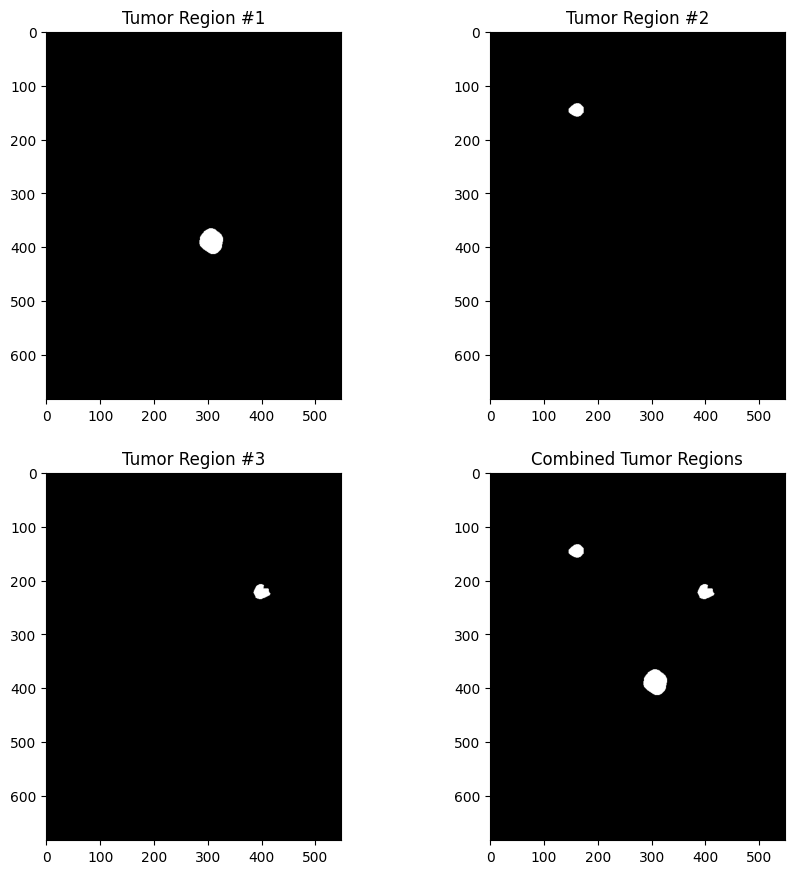

In [14]:
figure = plt.figure(figsize=(10.5, 10.5))

subplot = plt.subplot(2,2,1)
plt.imshow(Labeled_image == 33,cmap=plt.cm.gray)
plt.title('Tumor Region #1')

subplot = plt.subplot(2,2,2)
plt.imshow(Labeled_image == 28,cmap=plt.cm.gray)
plt.title('Tumor Region #2')

subplot = plt.subplot(2,2,3)
plt.imshow(Labeled_image == 30,cmap=plt.cm.gray)
plt.title('Tumor Region #3')

subplot = plt.subplot(2,2,4)
plt.imshow(black_image, cmap=plt.cm.gray)
plt.title('Combined Tumor Regions')

# Step 4

---

The connected components of the combined tumor mask are labeled again.
The area of each detected region is calculated in pixels and annotated
on the resulting image.

---

In [15]:
# Label connected components in the binary image
# and retrieve the total number of detected regions.
[Labeled_image, num_of_neighbors] = measure.label(black_image,  connectivity = 1, background = False, return_num = True)
Group_connected_list = image_tool.measure.regionprops(Labeled_image)

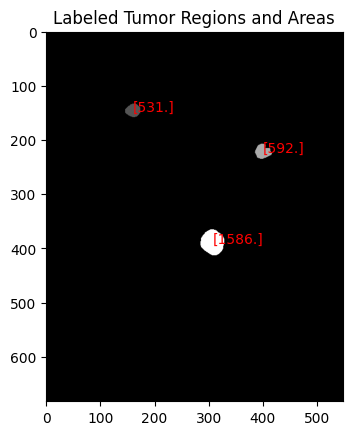

In [16]:
List_of_Areas=[]
List_of_Areas.append([d['area'] for d in Group_connected_list ] )
List_of_Areas = np.transpose(List_of_Areas)

plt.figure()  
plt.imshow(Labeled_image,cmap=plt.cm.gray)
plt.title('Labeled Tumor Regions and Areas')

for i in range(num_of_neighbors):
    plt.annotate(List_of_Areas[i], xy=(Group_connected_list[i].centroid[1],Group_connected_list[i].centroid[0]),color='red')

In [17]:
List_of_Areas

array([[ 531.],
       [ 592.],
       [1586.]])

# Step 5

---

A diamond-shaped structuring element is used for morphological processing
of the binary tumor mask.

The mask is dilated to expand the detected regions. The original binary
mask is then subtracted from the dilated image to obtain an approximation
of the outer boundary of each detected region.

The extracted boundaries are used for visualization of the detected
tumor regions.

---

In [18]:
# Convert the binary mask to an integer representation.
black_image = black_image.astype(np.int32)

In [19]:
Mask_Diamond = skimage.morphology.diamond(3)
Mask_Diamond = np.asarray(Mask_Diamond, dtype=np.int32)

Text(0.5, 1.0, 'Diamond Structuring Element')

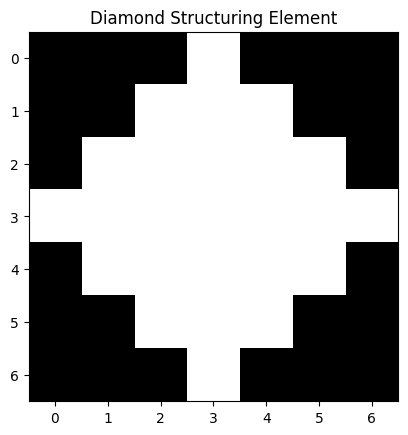

In [20]:
plt.imshow(Mask_Diamond,cmap=plt.cm.gray)
plt.title('Diamond Structuring Element')

In [21]:
Image_dilation = scipy.ndimage.binary_dilation(black_image, structure=Mask_Diamond)
Image_dilation = np.asarray(Image_dilation)

Text(0.5, 1.0, 'Image Dilation')

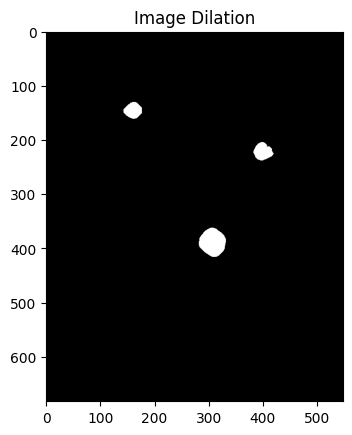

In [22]:
plt.imshow(Image_dilation,cmap=plt.cm.gray)
plt.title('Image Dilation')

In [23]:
outer_outline = Image_dilation-black_image

Text(0.5, 1.0, 'Detected Tumor Regions')

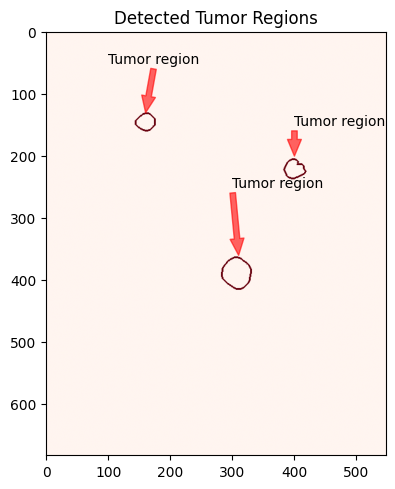

In [24]:
plt.figure(figsize=(5.5, 5.5))
plt.imshow(outer_outline, cmap ="Reds")
plt.annotate('Tumor region', xy=(160, 130), xytext=(100, 50), arrowprops=dict(alpha=0.6, fc='r', ec='r', headwidth=10))
plt.annotate('Tumor region', xy=(310, 360), xytext=(300, 250), arrowprops=dict(alpha=0.6, fc='r', ec='r', headwidth=10))
plt.annotate('Tumor region', xy=(400, 200), xytext=(400, 150), arrowprops=dict(alpha=0.6, fc='r', ec='r', headwidth=10))
plt.title('Detected Tumor Regions')

# Step 6

---

Morphological operations are applied to the combined binary mask in order
to demonstrate dilation, erosion, opening and closing.

The inner and outer boundaries of the detected regions are also extracted
for comparison.

---

In [25]:
# Apply binary dilation to expand the detected regions.
Image_dilation = scipy.ndimage.binary_dilation(
    black_image,
    structure=Mask_Diamond
)
Image_dilation = np.asarray(Image_dilation)

# Apply binary erosion to shrink the detected regions.
Image_erosion = scipy.ndimage.binary_erosion(
    black_image,
    structure=Mask_Diamond
)
Image_erosion = np.asarray(Image_erosion, dtype=np.int32)

# Apply morphological opening (erosion followed by dilation).
Image_opening = scipy.ndimage.binary_opening(
    black_image,
    structure=Mask_Diamond
)
Image_opening = np.asarray(Image_opening, dtype=np.int32)

# Apply morphological closing (dilation followed by erosion).
Image_closing = scipy.ndimage.binary_closing(
    black_image,
    structure=Mask_Diamond
)
Image_closing = np.asarray(Image_closing, dtype=np.int32)

# Extract the outer boundary of the detected regions.
outer_outline = Image_dilation - black_image

# Extract the inner boundary of the detected regions.
inner_outline = black_image - Image_erosion

Text(0.5, 1.0, 'Inner Outline')

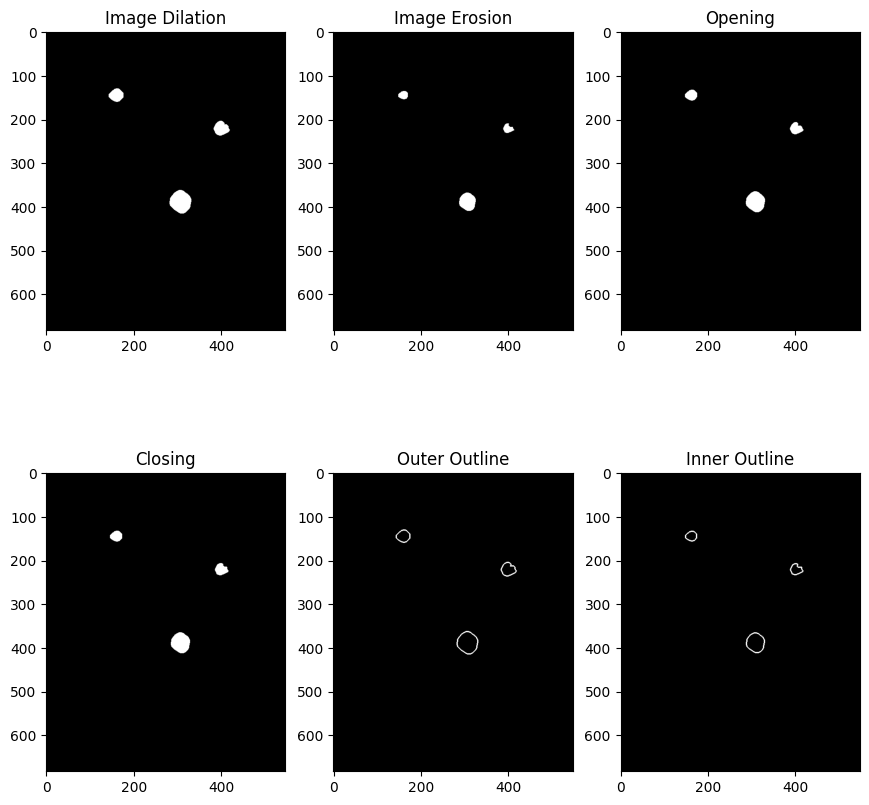

In [26]:
# Visualize the results of the morphological operations and boundary extraction.
figure = plt.figure(figsize=(10.5, 10.5))

subplot = figure.add_subplot(2,3,1)
plt.imshow(Image_dilation,cmap=plt.cm.gray)
subplot.set_title('Image Dilation')

subplot = figure.add_subplot(2,3,2)
plt.imshow(Image_erosion,cmap=plt.cm.gray)
subplot.set_title('Image Erosion')

subplot = figure.add_subplot(2,3,3)
plt.imshow(Image_opening, cmap=plt.cm.gray)
subplot.set_title('Opening')

subplot = figure.add_subplot(2,3,4)
plt.imshow(Image_closing, cmap=plt.cm.gray)
subplot.set_title('Closing')

subplot = figure.add_subplot(2,3,5)
plt.imshow(outer_outline,cmap=plt.cm.gray)
subplot.set_title('Outer Outline')

subplot = figure.add_subplot(2,3,6)
plt.imshow(inner_outline,cmap=plt.cm.gray)
subplot.set_title('Inner Outline')

Text(0.5, 1.0, 'Detected Tumor Regions')

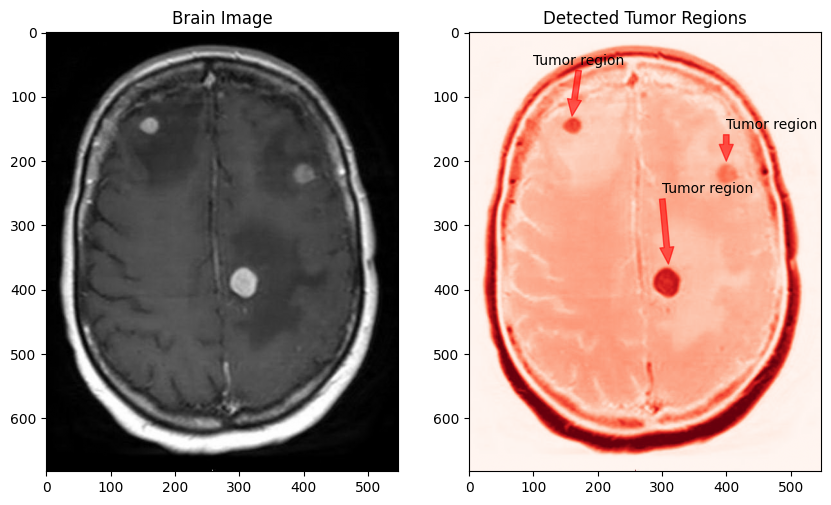

In [27]:
figure = plt.figure(figsize=(10, 10))

subplot = figure.add_subplot(1,2,1)
plt.imshow(grayscale_image,cmap=plt.cm.gray)
subplot.set_title('Brain Image')

subplot = figure.add_subplot(1,2,2)
plt.imshow(grayscale_image, cmap ="Reds")
plt.annotate('Tumor region', xy=(160, 130), xytext=(100, 50), arrowprops=dict(alpha=0.6, fc='r', ec='r', headwidth=10))
plt.annotate('Tumor region', xy=(310, 360), xytext=(300, 250), arrowprops=dict(alpha=0.6, fc='r', ec='r', headwidth=10))
plt.annotate('Tumor region', xy=(400, 200), xytext=(400, 150), arrowprops=dict(alpha=0.6, fc='r', ec='r', headwidth=10))
subplot.set_title('Detected Tumor Regions')